# CW1 (Ref/Def) - GPU Optimisation in TensorFlow

This notebook contains a convolutional neural network and an image preprocessing pipeline for an image classification task. The initial implementation is deliberately inefficient. Your task is to analyse its performance, identify the main bottlenecks, and improve the training workflow.

The focus of the assignment is **not** the dataset itself, nor the design of a state-of-the-art classifier. The main aim is to demonstrate that you can use TensorFlow tools, especially `tf.data` and the TensorBoard Profiler, to make a training pipeline faster and more effective.

You will train the model on **CIFAR-10**, a standard image classification dataset containing 60,000 RGB images of size 32×32 pixels. Each image belongs to one of 10 classes:

- airplane
- automobile
- bird
- cat
- deer
- dog
- frog
- horse
- ship
- truck

CIFAR-10 is used here because it is easy to load, compact enough for repeated experiments, and large enough to expose inefficient data pipelines and training choices.

The notebook includes a preprocessing function that performs resizing, rescaling, and data augmentation. You should consider how this pipeline can be made more efficient. In particular, investigate the effect of operations such as batching, caching, prefetching, and parallel mapping. Use the **TensorBoard Profiler** to support your analysis. You only need to profile a small number of batches; you do not need to profile the entire training run.

The CNN is intentionally simple and only moderately optimised. You should analyse the current architecture and training configuration, then make justified improvements. You may consider changes to convolutional blocks, activation functions, regularisation, optimiser settings, callbacks, and other training choices. Any changes should be motivated by evidence from your experiments.

You should first train the initial model at least once and record its behaviour. This gives you a baseline against which later improvements can be compared. You should then modify the pipeline and/or model and evaluate whether your changes improve:

1. training speed;
2. training accuracy;
3. validation and test accuracy;
4. generalisation behaviour.

You should include plots of the loss and accuracy curves, and you should discuss what the model appears to learn well and where it still fails. Where useful, show example predictions and comment on the types of images that are classified correctly or incorrectly.

You may add callbacks to control or monitor training, for example early stopping, learning-rate scheduling, checkpointing, or TensorBoard logging. This is not required, but it may help you produce a better analysis.

The starting code is deliberately suboptimal. It should learn something, but it should not be treated as a good final solution. You may change any code below except for the block that loads the dataset. In particular, do not replace CIFAR-10 with another dataset. Full marks require clear evidence of improvement in both computational performance and model performance.

# Exercise 1

Train the unoptimised model using the datasets provided. In your report, you should analyse both the performance (relating to the losses, mectrics, and classification of the 10 classes) and the efficiency (relating to the run times) of the model. Comment on why the model does not perform as well as expected or train in an efficient manner—you can support these comments with plots and by using the Tensorboard profiler.

In [ ]:
# Enter your module imports here, some modules are already provided

import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential, layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
# CodeGrade Tag Init1
# Do not edit, remove, or copy this cell

# Definition of some important variables

img_height = 32
img_width = 32
IMG_SIZE = (img_height,img_width)
NUM_CLASSES = 10
BATCH_SIZE = 32
EPOCHS = 20

In [ ]:
# CodeGrade Tag Init2
# Do not edit, remove, or copy this cell

# Load the dataset

train_ds, val_ds, test_ds = tfds.load(
    "cifar10",
    split=["train[:80%]", "train[80%:90%]", "test"],
    as_supervised=True,
)

# Names of the classes

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cifar10/incomplete.CDUGYO_3.0.2/cifar10-train.tfrecord-[0-9][0-9][0-9][0-9…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cifar10/incomplete.CDUGYO_3.0.2/cifar10-test.tfrecord-[0-9][0-9][0-9][0-9]…

Dataset cifar10 downloaded and prepared to /root/tensorflow_datasets/cifar10/3.0.2. Subsequent calls will reuse this data.


In [ ]:
# CodeGrade Tag Init3
# Do not edit, remove, or copy this cell

# Rotation layer

rotate = tf.keras.layers.RandomRotation(
    factor=20/360,
    fill_mode="nearest"
)

# Unoptimised Image Preprocessing functions.
# You should aim to optimise these in Exercise 2.

def img_process_train(image, label):
    """
    A preprocessing fuction for the training dataset. This function extracts
    the images and species label, the performs random augmentations before
    resizing and rescaling the images.
    """
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = rotate(image, training=True)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def img_process_test(image, label):
    """
    A preprocessing fuction for the test and validation datasets. This function
    extracts the images and species label, and resizes and rescales the images.
    """
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


In [ ]:
# CodeGrade Tag Init4
# Do not edit, remove, or copy this cell

# Unoptimised preprocessing pipeline
# You should aim to optimise these in Exercise 2.

train_ds = train_ds.map(img_process_train).batch(BATCH_SIZE)

val_ds = val_ds.map(img_process_test).batch(BATCH_SIZE)

test_ds = test_ds.map(img_process_test).batch(BATCH_SIZE)

- Using the Keras Sequential API, create a convolutional neural network for CIFAR-10 image classification. The model takes RGB images as input and outputs one score for each CIFAR-10 class.

  A few important points to consider:

  - The input images have shape `IMG_SIZE + (3,)`. For CIFAR-10, this is usually `(32, 32, 3)`.
  - The model should use two convolutional blocks.
  - Each block contains two `Conv2D` layers followed by one `MaxPooling2D` layer.
  - The first block uses 32 filters and the second block uses 64 filters.
  - The first two convolutions use a `4×4` kernel; the later convolutions use a `3×3` kernel.
  - Use `padding="same"` and `activation="relu"` in all convolutional layers.
  - After the convolutional feature extractor, use `Flatten`, followed by one dense hidden layer.
  - The final layer must be `Dense(NUM_CLASSES)` with no activation function. This means the model outputs logits.
  - If you compile the model using sparse categorical cross-entropy, use `from_logits=True`.
  - Use the layer names given below so that the model summary matches.

The following table lists all the layers of the stack:

| Layer name | Layer type | Output shape, assuming `IMG_SIZE = (32, 32)` | Notes |
|---|---|---|---|
| `Input` | `InputLayer` | `(None, 32, 32, 3)` | Input RGB images |
| `Conv_1` | `Conv2D` | `(None, 32, 32, 32)` | `4×4` conv, 32 filters, ReLU, `padding="same"` |
| `Conv_2` | `Conv2D` | `(None, 32, 32, 32)` | `4×4` conv, 32 filters, ReLU, `padding="same"` |
| `Pool_1` | `MaxPooling2D` | `(None, 16, 16, 32)` | Reduces spatial size by a factor of 2 |
| `Conv_3` | `Conv2D` | `(None, 16, 16, 64)` | `3×3` conv, 64 filters, ReLU, `padding="same"` |
| `Conv_4` | `Conv2D` | `(None, 16, 16, 64)` | `3×3` conv, 64 filters, ReLU, `padding="same"` |
| `Pool_2` | `MaxPooling2D` | `(None, 8, 8, 64)` | Reduces spatial size by a factor of 2 |
| `Flatten` | `Flatten` | `(None, 4096)` | Flattens the feature maps |
| `dense_1` | `Dense` | `(None, 512)` | Dense layer with ReLU activation |
| `Output` | `Dense` | `(None, NUM_CLASSES)` | Output logits for the classes |

In [ ]:
# CodeGrade Tag Ex1a

def create_model_unoptimised():

    model = Sequential([
        layers.Input(shape=IMG_SIZE + (3,), name="Input"),

        layers.Conv2D(32, 4, padding="same", activation="relu", name="Conv_1"),
        layers.Conv2D(32, 4, padding="same", activation="relu", name="Conv_2"),
        layers.MaxPooling2D(name="Pool_1"),

        layers.Conv2D(64, 3, padding="same", activation="relu", name="Conv_3"),
        layers.Conv2D(64, 3, padding="same", activation="relu", name="Conv_4"),
        layers.MaxPooling2D(name="Pool_2"),

        layers.Flatten(name="Flatten"),

        layers.Dense(512, activation="relu", name="dense_1"),
        layers.Dense(NUM_CLASSES, name="Output")
    ])

    return model

- Create a version of the model and print the model summary to confirm it has the same architecture as the one provided above.

In [ ]:
# CodeGrade Tag Ex1b

model = create_model_unoptimised()

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Conv_1 (Conv2D)                 │ (None, 32, 32, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_2 (Conv2D)                 │ (None, 32, 32, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_1 (MaxPooling2D)           │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_3 (Conv2D)                 │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv_4 (Conv2D)                 │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Pool_2 (MaxPooling2D)           │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │     2,097,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,176,202 (8.30 MB)

 Trainable params: 2,176,202 (8.30 MB)

 Non-trainable params: 0 (0.00 B)

- Compile the model for multi-class image classification.

  Use the Adam optimiser, sparse categorical cross-entropy as the loss, and accuracy as the evaluation metric. Since the output layer returns logits rather than probabilities, make sure that the loss is configured with `from_logits=True`.

In [ ]:
# CodeGrade Tag Ex1c

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

- Train the model using the training dataset, and use the validation dataset to monitor performance after each epoch. Store the returned training history.

In [ ]:
# CodeGrade Tag Ex1d

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 50s 36ms/step - accuracy: 0.3993 - loss: 1.6398 - val_accuracy: 0.5056 - val_loss: 1.3745
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.5268 - loss: 1.3091 - val_accuracy: 0.5624 - val_loss: 1.1934
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.5835 - loss: 1.1647 - val_accuracy: 0.6084 - val_loss: 1.0845
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 35s 28ms/step - accuracy: 0.6173 - loss: 1.0787 - val_accuracy: 0.6400 - val_loss: 1.0061
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.6417 - loss: 1.0041 - val_accuracy: 0.6424 - val_loss: 1.0055
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.6635 - loss: 0.9495 - val_accuracy: 0.6584 - val_loss: 0.9709
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 37s 30ms/step - accuracy: 0.6818 - loss: 0.8993 - val_accuracy: 0.6648 - val_loss: 0.9638
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.6960 -

- Plot the training history to compare the model's behaviour on the training and validation datasets. You should produce one plot for the loss curves and one plot for the accuracy curves, with clear labels and legends.

  In the report you can use these plots to comment on whether the model is learning effectively and whether there is evidence of overfitting or underfitting.

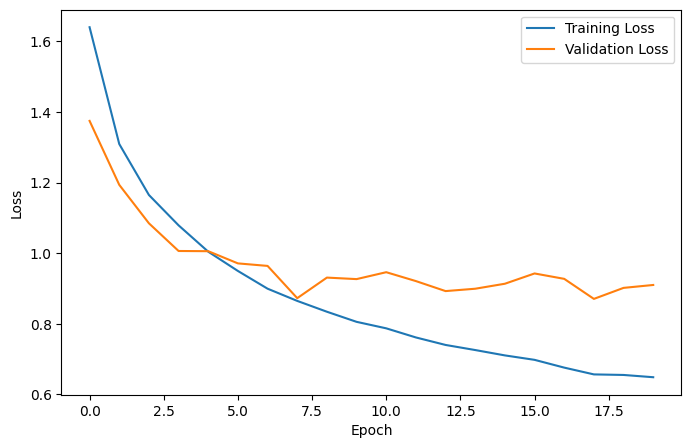

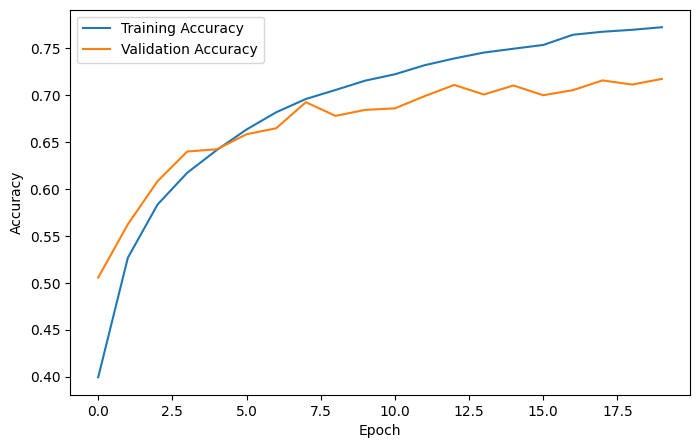

In [ ]:
# CodeGrade Tag Ex1e

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

- Plot a selection of example images from the test dataset together with the model's predicted class and the true class.

  In the report, you can use these examples to begin assessing what the model is classifying correctly and where it is making mistakes.

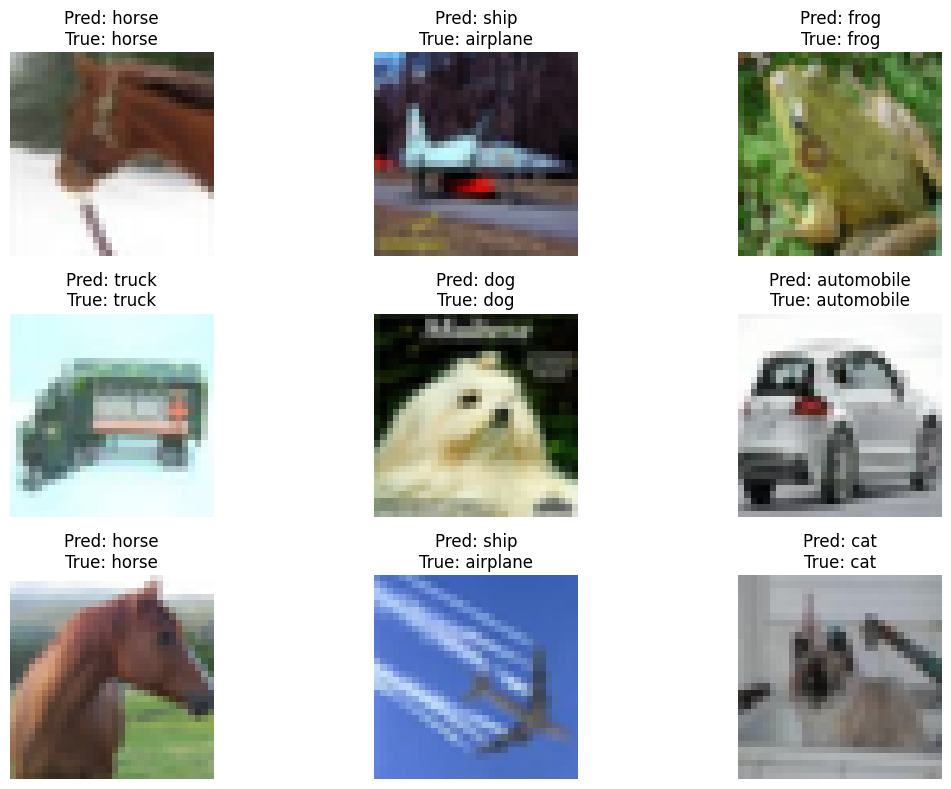

In [ ]:
# CodeGrade Tag Ex1f

images, labels = next(iter(test_ds))
predictions = model.predict(images, verbose=0)
pred_classes = tf.argmax(predictions, axis=1)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title(
        f"Pred: {class_names[pred_classes[i]]}\nTrue: {class_names[labels[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# Exercise 2

In this exercise you will take the `tf.data` pipeline from Exercise 1 and optimise it.

The aim is to make the input pipeline more efficient while preserving the correct training behaviour. You should think carefully about which operations should be cached, which operations are random augmentations, and where it is appropriate to use techniques such as batching, parallel mapping, and prefetching.

You should not only change the code, but also explain the reasoning behind your choices in your report. In particular, consider whether your pipeline reduces unnecessary repeated work, keeps the GPU better supplied with data, and still applies data augmentation in a suitable way during training.

In [ ]:
# CodeGrade Tag Init4
# Do not edit, remove, or copy this cell

# Load the dataset again

train_ds, val_ds, test_ds = tfds.load(
    "cifar10",
    split=["train[:80%]", "train[80%:90%]", "test"],
    as_supervised=True,
)

# Names of the classes

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

- Rewrite from scratch the preprocessing functions to improve the efficiency of the model (e.g. you could have separate functions for deterministic preprocessing and random data augmentation). Comment on your changes in your report, specifying why you made them.

In [ ]:
# CodeGrade Tag Ex2a

def preprocess(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = rotate(image, training=True)
    return image, label

- Build an efficient `tf.data` pipeline for the training, validation, and test datasets. You should decide how to combine batching, preprocessing, augmentation, caching, parallel mapping, and prefetching so that the pipeline is appropriate for training and evaluation. In your report, justify the order of these operations and explain how your choices affect efficiency and model performance.

In [ ]:
# CodeGrade Tag Ex2b

AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    train_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .cache()
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .map(augment, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .cache()
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Exercise 3

In this exercise you will modify the architecture of the unoptimised model from exercise 1 to improve its performance.

The baseline model from Exercise 1 is deliberately simple and not especially well regularised. Your task is to design a more effective CNN for CIFAR-10 by making justified architectural changes.

You should also consider the trade-off between predictive performance and computational cost. A larger model is not automatically better: your goal is to improve validation and test performance in a way that you can justify from the training curves, evaluation plots, and examples of predictions.

- Look at the unoptimised model from exercise 1. Then, modify the design of the unoptimised model to improve the performance on the test dataset. You may consider changing the settings of the layers in the model, adding or removing layers. Comment on your changes in your report.

In [22]:
# CodeGrade Tag Ex3

def create_model_optimised():

    model = Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),

        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES)
    ])

    return model

# Exercise 4
In this exercise you will train your optimised model and demonstrate the improvements in performance and efficiency.

In your report, you should compare the optimised version with the baseline from Exercise 1, using evidence from the training history, validation performance, test performance, and runtime behaviour. Your aim is not only to show that the final model obtains a better score, but to explain how the changes to the data pipeline and model architecture affected the results.

- Create a version of the model and print the model summary.

In [ ]:
# CodeGrade Tag Ex4a

model = create_model_optimised()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,049,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,194,538 (4.56 MB)

 Trainable params: 1,194,090 (4.56 MB)

 Non-trainable params: 448 (1.75 KB)

- Compile the model for multi-class image classification.

  You are allowed to change the optimiser settings, but keep accuracy as the evaluation metric. If you make any change at all, comment on it in your report, specifying why you made it.

In [ ]:
# CodeGrade Tag Ex4b

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=["accuracy"]
)

- Train the model using the training dataset, and use the validation dataset to monitor performance after each epoch. Store the returned training history.

In [18]:
# CodeGrade Tag Ex4c

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 24s 13ms/step - accuracy: 0.3787 - loss: 1.7440 - val_accuracy: 0.5164 - val_loss: 1.3586
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 7ms/step - accuracy: 0.5144 - loss: 1.3592 - val_accuracy: 0.5588 - val_loss: 1.3364
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.5861 - loss: 1.1860 - val_accuracy: 0.6326 - val_loss: 1.0423
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.6273 - loss: 1.0828 - val_accuracy: 0.6824 - val_loss: 0.9129
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.6526 - loss: 1.0034 - val_accuracy: 0.7322 - val_loss: 0.7712
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.6777 - loss: 0.9408 - val_accuracy: 0.7138 - val_loss: 0.8330
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.6909 - loss: 0.9010 - val_accuracy: 0.7206 - val_loss: 0.8818
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.7064 - loss: 0.8620

- Plot the training history to compare the model's behaviour on the training and validation datasets. You should produce one plot for the loss curves and one plot for the accuracy curves, with clear labels and legends.

  In the report you can use these plots to comment on whether the model is learning effectively and whether there is evidence of overfitting or underfitting.

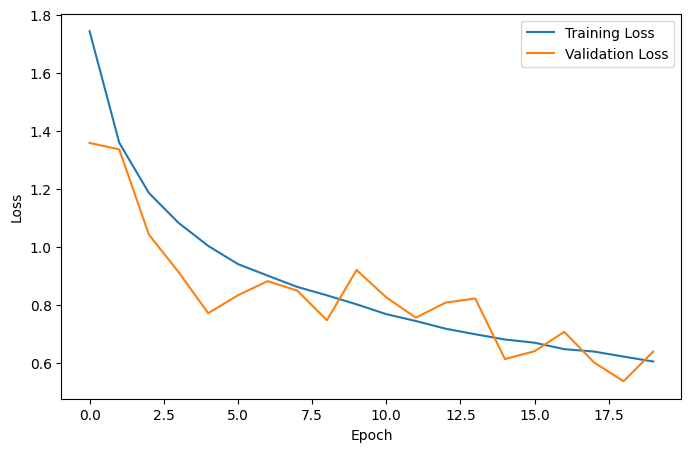

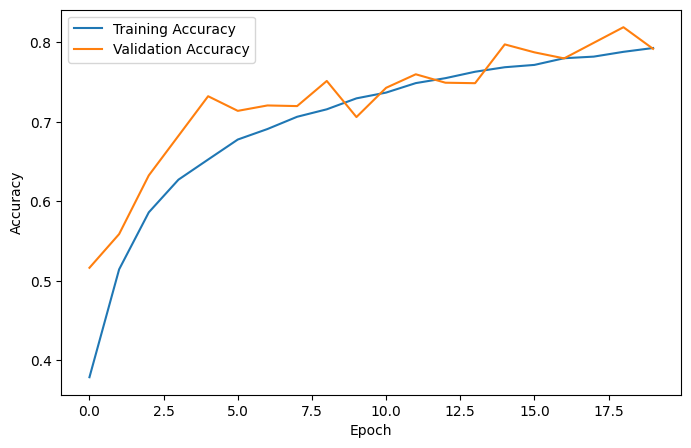

In [19]:
# CodeGrade Tag Ex4d

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

- Plot a selection of example images from the test dataset together with the model's predicted class and the true class.

  In the report, you can use these examples to begin assessing what the model is classifying correctly and where it is making mistakes.

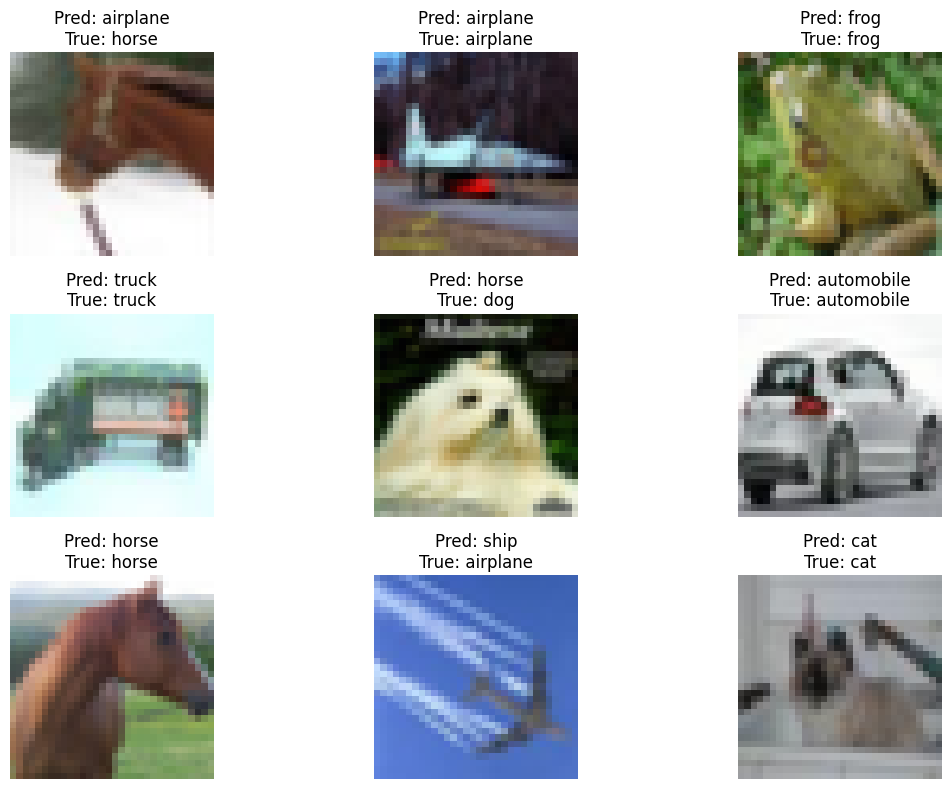

In [20]:
# CodeGrade Tag Ex4e

images, labels = next(iter(test_ds))
predictions = model.predict(images, verbose=0)
pred_classes = tf.argmax(predictions, axis=1)

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i])
    plt.title(
        f"Pred: {class_names[pred_classes[i]]}\nTrue: {class_names[labels[i]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

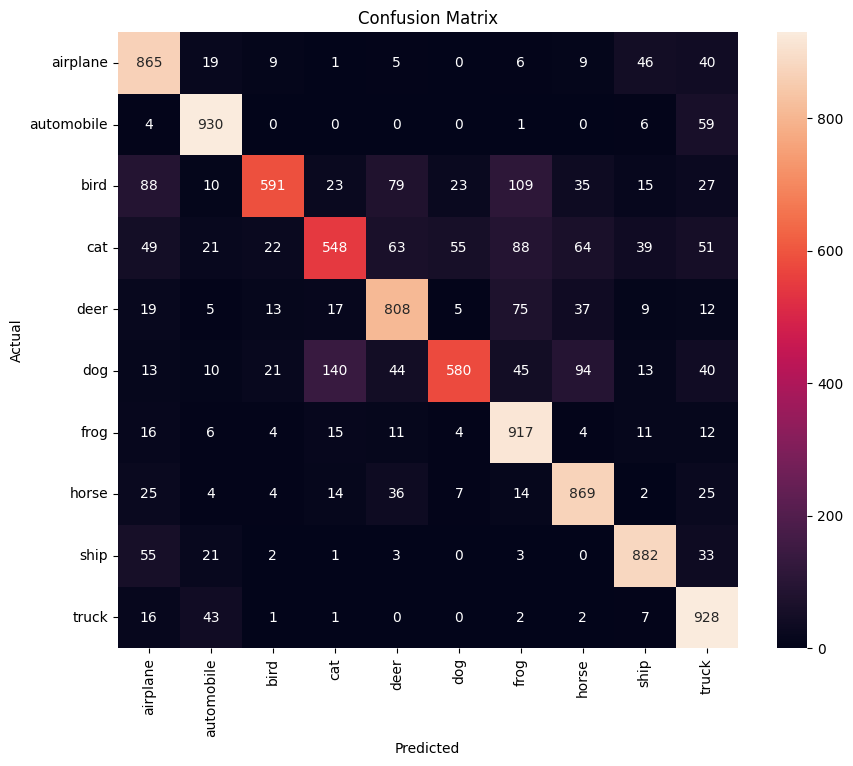

In [21]:
# CodeGrade Tag Ex4f

from sklearn.metrics import confusion_matrix
import seaborn as sns

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()